# Assignment 07 — Knowledge Graph (KB), RAG và agent

## 1. Mở đầu: lịch sử, vai trò và ý nghĩa

**Lịch sử.** Ý tưởng biểu diễn tri thức thành thực thể và quan hệ có gốc từ hệ cơ sở tri thức và Semantic Web. Năm 2012, Google giới thiệu Knowledge Graph cho tìm kiếm dựa trên thực thể và quan hệ. Năm 2020, Lewis và cộng sự công bố *Retrieval-Augmented Generation* (RAG): mô hình sinh có thể tham chiếu kho tài liệu truy xuất được thay vì chỉ dựa vào tham số đã học. Xem [Google Research, 2012](https://research.google/blog/new-challenges-in-computer-science-research/) và [Lewis et al., 2020](https://arxiv.org/abs/2005.11401).

**Vai trò.** Knowledge Base (KB) lưu sự kiện có cấu trúc, giúp truy vấn quan hệ và kiểm tra nguồn. RAG tìm các đoạn liên quan rồi đưa chúng vào ngữ cảnh cho mô hình ngôn ngữ, giúp câu trả lời bám vào dữ liệu có thể cập nhật. Agent phối hợp công cụ graph, phép tính chính xác và RAG để xử lý các loại câu hỏi khác nhau. Cả ba không tự biến dữ liệu quan sát thành dự báo hoặc kết luận nhân quả.

**Dataset:** 100.000 bản ghi và nhãn `diabetes` nhị phân. Bài tập trả lời thống kê trong dataset, không chẩn đoán cá nhân.

## 2. Knowledge Graph / Knowledge Base

Knowledge Graph gồm **nút** (thực thể hoặc nhóm), **cạnh có nhãn** (quan hệ) và thuộc tính. Một sự kiện có thể viết dưới dạng bộ ba $(s,p,o)$, ví dụ `(year:2023, has_month, month:2023-12)`. Graph trong bài dùng `networkx.DiGraph`; node giữ số liệu, cạnh giữ quan hệ. Truy vấn graph đi theo ID hoặc cạnh, nên câu hỏi đã biết khóa (ngày hay nhóm) được trả lời bằng dữ kiện chính xác.

Các bước xây KB: (1) kiểm tra schema và giá trị thiếu, (2) chọn thực thể/quan hệ, (3) chuẩn hóa ID để không tạo nút trùng, (4) nạp thuộc tính từ CSV, (5) kiểm tra truy vấn so với dữ liệu gốc. **Giới hạn:** graph chỉ biết các sự kiện đã nạp; thiếu cạnh không có nghĩa một quan hệ là sai. Thuộc tính số phải được tính từ CSV, không yêu cầu LLM ước lượng.

Ở diabetes_large, graph dùng nút dataset, nhóm (gender, smoking_history, age_group, hypertension, heart_disease) và kết quả nhãn 0/1. Mỗi nhóm lưu count, positive, rate. Không tạo nút từng người bệnh; số liệu chỉ mô tả mẫu dữ liệu.

### 2.1. Mô hình hình thức, truy vấn và xuất xứ

Gọi graph là $G=(V,E)$, với $V$ là tập nút và $E\subseteq V\times R\times V$ là các cạnh có nhãn quan hệ thuộc $R$. Bộ ba `(subject, predicate, object)` diễn đạt một liên kết; thuộc tính số và ngày được giữ ở node. `networkx.DiGraph` là lựa chọn gọn cho bài tập. RDF/OWL là hướng biểu diễn theo chuẩn Semantic Web khi cần chia sẻ ontology và suy luận trên nhiều hệ thống, nhưng không cần thiết cho hai CSV này.

**Truy vấn:** trước hết phân tích khóa thực thể trong câu hỏi; sau đó tra node và, nếu cần, duyệt các cạnh liên quan. Truy vấn thống kê cần lọc bản ghi gốc hoặc aggregate đã được kiểm chứng. Mỗi kết quả trả ID nguồn để đối chiếu CSV. Kiểm tra KB bằng đếm nút/cạnh, tính duy nhất của ID, giá trị thiếu và đối chiếu phép nhóm. Graph không tự chứa kiến thức y khoa hay tin tức thị trường ngoài CSV.

## 4. Thiết lập và đọc dữ liệu
Notebook gọi lại các hàm trong `deploy.py`. Cần `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `networkx`, `flask`, `torch`; chỉ cần thêm `transformers>=4.51 accelerate` khi chạy phần Qwen3.

Ví dụ cài thư viện vào đúng môi trường Python đang chạy notebook:

```bash
python -m pip install pandas matplotlib scikit-learn networkx flask torch "transformers>=4.51,<5" accelerate
```

In [1]:
import importlib.util
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

candidates = [Path("../deploy.py"), Path("deploy.py"), Path("src/Assignment 07/diabetes_large/deploy.py")]
deploy_path = next((p.resolve() for p in candidates if p.exists()), None)
if deploy_path is None:
    raise FileNotFoundError("Không tìm thấy deploy.py của diabetes_large")
spec = importlib.util.spec_from_file_location("diabetes_a07", deploy_path)
a07 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(a07)
df = a07.load_data()
print("Nguồn:", a07.DATA_PATH)
print("Kích thước:", df.shape)
display(df.head())

Nguồn: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 07/diabetes_large/data/diabetes_prediction_dataset.csv
Kích thước: (100000, 10)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,age_group
0,Female,80.0,0,1,never,25.19,6.6,140,0,60+
1,Female,54.0,0,0,No Info,27.32,6.6,80,0,40-59
2,Male,28.0,0,0,never,27.32,5.7,158,0,18-39
3,Female,36.0,0,0,current,23.45,5.0,155,0,18-39
4,Male,76.0,1,1,current,20.14,4.8,155,0,60+


## 5. Mô tả và kiểm tra chất lượng dữ liệu
Kiểm tra kiểu cột, missing, trùng dòng và mất cân bằng nhãn. Dòng trùng có thể là các quan sát cùng đặc điểm; không tự động xóa để tránh thay đổi thống kê gốc.

In [2]:
audit = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique()})
display(audit)
print("Dòng trùng:", df[a07.COLUMNS].duplicated().sum())
print("Phân bố nhãn:", df["diabetes"].value_counts().sort_index().to_dict())
print("Tỷ lệ nhãn 1:", f"{df['diabetes'].mean():.2%}")
display(df[["age", "bmi", "HbA1c_level", "blood_glucose_level"]].describe().T)

,dtype,missing,unique
gender,str,0,3
age,float64,0,102
hypertension,int64,0,2
heart_disease,int64,0,2
smoking_history,str,0,6
bmi,float64,0,4247
HbA1c_level,float64,0,18
blood_glucose_level,int64,0,18
diabetes,int64,0,2
age_group,str,0,4


Dòng trùng: 3854
Phân bố nhãn: {0: 91500, 1: 8500}
Tỷ lệ nhãn 1: 8.50%


,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.885856,22.516840,0.08,24.00,43.00,60.00,80.00
bmi,100000.0,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,5.527507,1.070672,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.058060,40.708136,80.00,100.00,140.00,159.00,300.00


## 6. EDA: phân bố nhãn và thuộc tính
Histogram và biểu đồ cột mô tả mẫu. Tỷ lệ giữa các nhóm có thể khác nhau, nhưng dữ liệu quan sát không chứng minh nguyên nhân. Nhãn 1 ít hơn nhãn 0 nên cần đọc cả số lượng lẫn tỷ lệ.

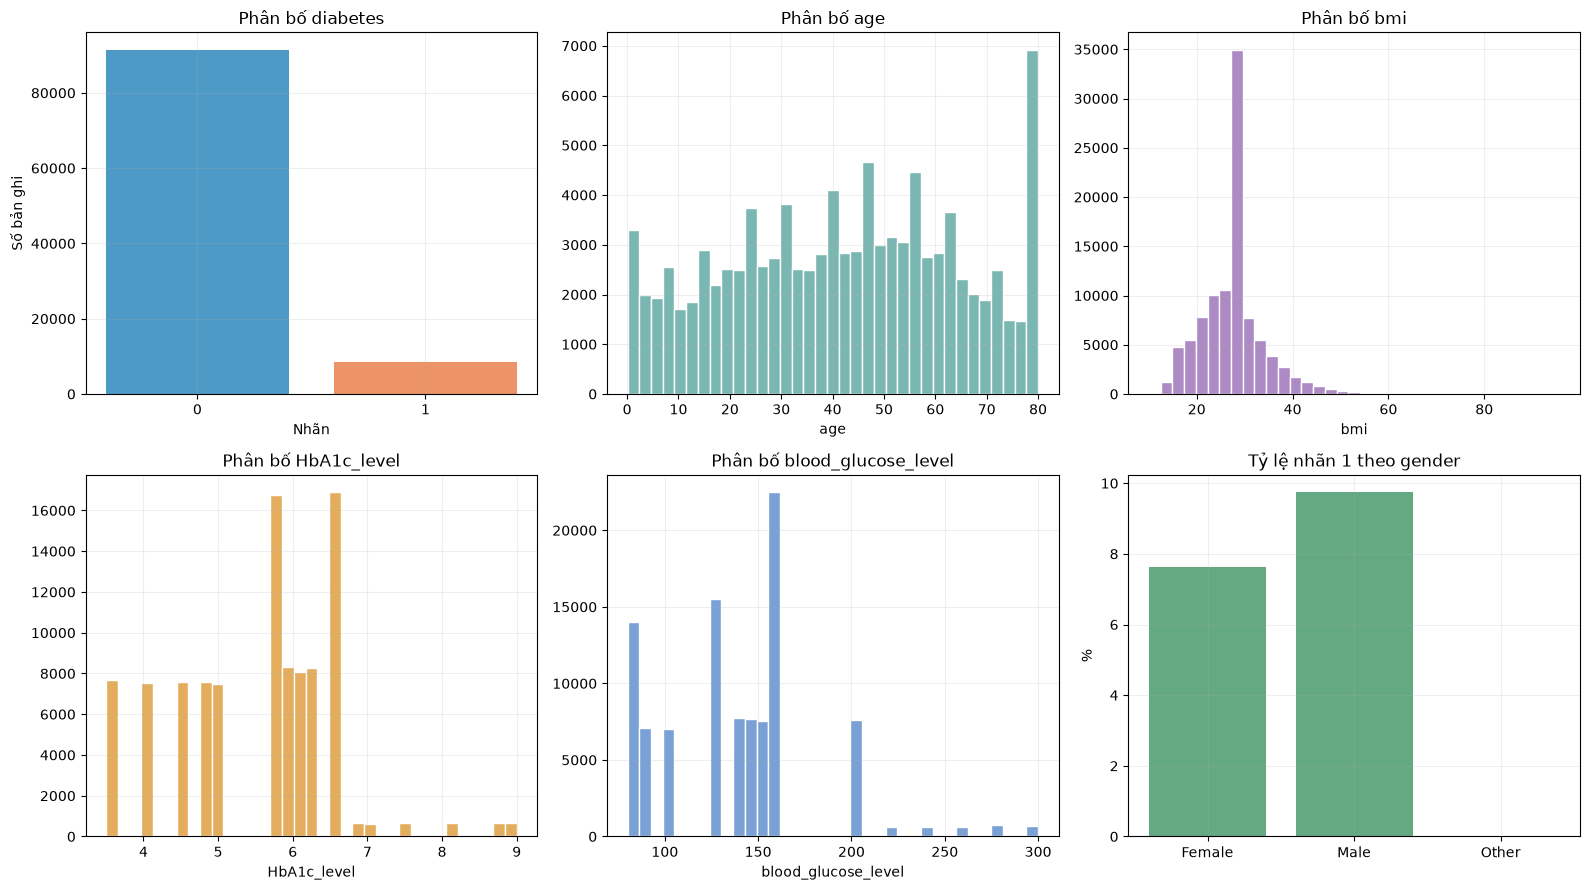

,count,rate
smoking_history,,
No Info,35816,0.040596
current,9286,0.102089
ever,4004,0.117882
former,9352,0.170017
never,35095,0.095341
not current,6447,0.107027


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
counts = df["diabetes"].value_counts().sort_index()
axes[0,0].bar(counts.index.astype(str), counts.values, color=["#4e9ac7", "#ec9467"])
axes[0,0].set(title="Phân bố diabetes", xlabel="Nhãn", ylabel="Số bản ghi")
for ax, col, color in [(axes[0,1],"age","#7bb7b2"),(axes[0,2],"bmi","#ae8ac4"),
                       (axes[1,0],"HbA1c_level","#e4ad5d"),(axes[1,1],"blood_glucose_level","#79a1d6")]:
    ax.hist(df[col], bins=35, color=color, edgecolor="white")
    ax.set(title=f"Phân bố {col}", xlabel=col)
by_gender = df.groupby("gender")["diabetes"].agg(["size","mean"])
axes[1,2].bar(by_gender.index, by_gender["mean"]*100, color="#65a982")
axes[1,2].set(title="Tỷ lệ nhãn 1 theo gender", ylabel="%")
for ax in axes.flat: ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
display(df.groupby("smoking_history")["diabetes"].agg(["size","mean"]).rename(columns={"size":"count","mean":"rate"}))

## 7. Xây KB và kiểm chứng thống kê
Các nhóm tuổi được xác định **cho mục đích EDA**: 0–17, 18–39, 40–59, 60+. Đây không phải ngưỡng chẩn đoán. Truy vấn graph phải khớp phép tính trực tiếp trên CSV.

In [4]:
graph = a07.build_graph(df)
print("Số nút:", graph.number_of_nodes(), "| Số cạnh:", graph.number_of_edges())
for triple in a07.graph_triples(graph): print(triple)
node = a07.query_graph(graph, "gender", "Female")
print("Nhóm Female:", node)
raw = df.loc[df["gender"].eq("Female"), "diabetes"]
assert node["count"] == len(raw)
assert node["positive"] == int(raw.sum())

Số nút: 20 | Số cạnh: 51
('dataset:diabetes_large', 'has_cohort', 'cohort:gender:Female')
('cohort:gender:Female', 'positive_count', 'outcome:1')
('cohort:gender:Female', 'negative_count', 'outcome:0')
('dataset:diabetes_large', 'has_cohort', 'cohort:gender:Male')
('dataset:diabetes_large', 'has_cohort', 'cohort:gender:Other')
('dataset:diabetes_large', 'has_cohort', 'cohort:smoking_history:No Info')
('dataset:diabetes_large', 'has_cohort', 'cohort:smoking_history:current')
('dataset:diabetes_large', 'has_cohort', 'cohort:smoking_history:ever')
Nhóm Female: {'kind': 'cohort', 'dimension': 'gender', 'value': 'Female', 'count': 58552, 'positive': 4461, 'rate': 0.0761886869790955}


## 3. Retrieval-Augmented Generation (RAG)

Pipeline: `CSV → tài liệu có ID nguồn → TF-IDF → truy xuất top-k → ngữ cảnh → Qwen3-0.6B → câu trả lời`. Mỗi tài liệu là một đoạn ngắn có ID ổn định. `TfidfVectorizer(analyzer="char_wb", ngram_range=(3,5))` phù hợp khi câu hỏi có tiếng Việt lẫn tên cột tiếng Anh, không cần tải embedding model. Điểm cosine dùng để xếp hạng; nếu không đủ bằng chứng thì agent từ chối trả lời.

Truy xuất tốt **không bảo đảm** mô hình sinh luôn đúng. Vì thế, số liệu được lấy từ graph/CSV, còn mô hình chỉ diễn đạt từ tài liệu truy xuất và giao diện luôn hiển thị ID nguồn. Qwen3 chạy cục bộ bằng Transformers, tải model vào cache ở lần dùng đầu. Theo [model card Qwen3-0.6B](https://huggingface.co/Qwen/Qwen3-0.6B), cần Transformers hỗ trợ Qwen3 (từ 4.51); sau khi đã tải, không cần API.

Ở diabetes_large, corpus gồm tóm tắt toàn dataset và một tài liệu cho từng nhóm. ID như `DIABETES:gender:Female` trỏ đến phép nhóm từ CSV, không đến hồ sơ một người. Các câu hỏi thống kê dùng graph/CSV để giữ độ chính xác.

### 3.1. Từ tài liệu đến điểm truy xuất

Mỗi tài liệu được tạo có quy tắc từ CSV: ID nguồn, nội dung ngắn và các giá trị có đơn vị. TF-IDF tăng trọng số từ/cụm ký tự đặc trưng của một tài liệu và giảm trọng số phần xuất hiện khắp corpus. Với vector truy vấn $q$ và tài liệu $d$, điểm cosine là $\operatorname{sim}(q,d)=\frac{q\cdot d}{\lVert q\rVert\lVert d\rVert}$. Notebook dùng n-gram ký tự 3–5 và lấy tối đa 4 tài liệu có điểm từ 0,10. Điểm này là mức liên quan văn bản, không phải độ tin cậy thống kê.

**Sinh câu trả lời:** prompt chứa câu hỏi và các tài liệu truy xuất, yêu cầu mô hình chỉ dùng bằng chứng đó. Mô hình có thể diễn đạt sai dù truy xuất đúng, nên agent tách phép tính khỏi sinh văn bản và luôn trả danh sách nguồn. Câu hỏi không có dữ kiện tương ứng phải được báo thiếu dữ liệu. Không đưa toàn bộ 100.000 dòng diabetes hoặc toàn bộ phiên Amazon vào prompt: văn bản quá dài, khó kiểm tra và không cần cho truy vấn tổng hợp.

### 3.2. Agent và đánh giá

Agent là bộ điều phối: nhận câu hỏi → chọn công cụ phù hợp → lấy bằng chứng → trả câu trả lời cùng `sources` và `tools`. Bộ chọn có quy tắc rõ ràng: ngày/nhóm cụ thể đi qua graph; phép gộp số qua CSV; câu hỏi mô tả qua RAG. Với mô hình nhỏ, cách này giữ phép tính chính xác và giúp tái lập kết quả.

Đánh giá riêng từng tầng: (1) **KB** đối chiếu node/aggregate với CSV; (2) **retrieval** kiểm tra nguồn mong đợi có trong top-k; (3) **generation** kiểm tra câu trả lời có được bằng chứng hỗ trợ; (4) **agent** kiểm tra định tuyến, câu hỏi ngoài phạm vi và lỗi đầu vào. Một câu trả lời trôi chảy mà không có nguồn phù hợp vẫn là lỗi.

## 8. Lập chỉ mục và thử truy xuất
Xem top-k tài liệu và điểm cosine; tài liệu không tự đưa ra chẩn đoán hay quan hệ nhân quả.

In [5]:
documents = a07.build_documents(df)
vectorizer, matrix = a07.build_index(documents)
print("Tài liệu:", len(documents), "| Ma trận TF-IDF:", matrix.shape)
for item in a07.retrieve("Tóm tắt diabetes gender Female", documents, vectorizer, matrix):
    print(item["id"], "score=", item["score"], "|", item["text"][:120])

Tài liệu: 18 | Ma trận TF-IDF: (18, 1351)
DIABETES:gender:Female score= 0.4447 | Nhóm gender=Female: 58552 bản ghi, 4461 nhãn diabetes=1, tỷ lệ 7.62%. Tỷ lệ mô tả dataset, không chứng minh quan hệ nhân
DIABETES:gender:Male score= 0.2921 | Nhóm gender=Male: 41430 bản ghi, 4039 nhãn diabetes=1, tỷ lệ 9.75%. Tỷ lệ mô tả dataset, không chứng minh quan hệ nhân q
DIABETES:gender:Other score= 0.2535 | Nhóm gender=Other: 18 bản ghi, 0 nhãn diabetes=1, tỷ lệ 0.00%. Tỷ lệ mô tả dataset, không chứng minh quan hệ nhân quả.
DIABETES:overall score= 0.15 | Dataset diabetes_large có 100000 bản ghi, 8500 nhãn diabetes=1, 91500 nhãn diabetes=0; tỷ lệ nhãn 1 là 8.50%. Các trường


## 9. Agent: graph, thống kê và RAG
Câu hỏi tỷ lệ theo nhóm đi qua graph; tỷ lệ toàn tập tính từ CSV; câu hỏi mô tả dùng RAG. `generate=False` hiển thị chứng cứ truy xuất để chạy notebook khi chưa tải model.

In [6]:
agent = a07.DiabetesAgent(df)
for question in ["Tỷ lệ diabetes ở nữ là bao nhiêu?", "Tỷ lệ diabetes toàn dataset là bao nhiêu?", "Tỷ lệ diabetes nhóm 60+ là bao nhiêu?"]:
    print("\nHỏi:", question)
    print(agent.ask(question, generate=False))
print("\nRAG không sinh:", agent.ask("Tóm tắt dữ liệu diabetes_large", generate=False))


Hỏi: Tỷ lệ diabetes ở nữ là bao nhiêu?
{'answer': 'Nhóm gender=Female có 58,552 bản ghi; 4,461 nhãn diabetes=1; tỷ lệ 7.62%.', 'sources': ['DIABETES:gender:Female'], 'tools': ['knowledge_graph']}

Hỏi: Tỷ lệ diabetes toàn dataset là bao nhiêu?
{'answer': 'CSV có 100,000 bản ghi; 8,500 nhãn diabetes=1; tỷ lệ 8.50%.', 'sources': ['DIABETES:overall'], 'tools': ['csv_statistics']}

Hỏi: Tỷ lệ diabetes nhóm 60+ là bao nhiêu?
{'answer': 'Nhóm age_group=60+ có 25,055 bản ghi; 4,932 nhãn diabetes=1; tỷ lệ 19.68%.', 'sources': ['DIABETES:age_group:60+'], 'tools': ['knowledge_graph']}

RAG không sinh: {'answer': 'Dataset diabetes_large có 100000 bản ghi, 8500 nhãn diabetes=1, 91500 nhãn diabetes=0; tỷ lệ nhãn 1 là 8.50%. Các trường: gender, age, hypertension, heart_disease, smoking_history, bmi, HbA1c_level, blood_glucose_level, diabetes. Đây là dữ liệu quan sát, không phải chẩn đoán.', 'sources': ['DIABETES:overall'], 'tools': ['rag_retrieval']}


## 10. Chạy mô hình ngôn ngữ cục bộ
Đặt `RUN_LOCAL_LLM=True` sau khi cài `transformers>=4.51 accelerate` và cho phép tải Qwen3-0.6B lần đầu. Model nhận ngữ cảnh truy xuất; câu trả lời vẫn cần được kiểm tra theo nguồn. Cell này chạy Qwen3 khi thực thi notebook; lần tải đầu cần Internet và các thư viện đã nêu.

In [7]:
RUN_LOCAL_LLM = True
if RUN_LOCAL_LLM:
    print(agent.ask("Tóm tắt dữ liệu diabetes_large", generate=True))
else:
    print("Đặt RUN_LOCAL_LLM=True để kiểm tra lượt sinh bằng Qwen3 cục bộ.")

/opt/miniconda3/envs/ISD/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'answer': 'Tóm tắt dữ liệu diabetes_large: có 100,000 bản ghi, 8500 nhãn 1 và 91500 nhãn 0, tỷ lệ nhãn 1 là 8.5%.', 'sources': ['DIABETES:overall'], 'tools': ['rag_retrieval', 'local_llm']}


## 11. Deploy và kết luận
CLI: `python deploy.py --question "Tỷ lệ diabetes ở nữ là bao nhiêu?"`. Web: `python deploy.py --web --port 8008`, rồi mở `http://127.0.0.1:8008`. API `POST /api/chat` nhận `{"question":"..."}` và trả `answer`, `sources`, `tools`. Kết quả chỉ mô tả dataset, không dùng để chẩn đoán hoặc tư vấn điều trị.